In [2]:
%load_ext autoreload
%autoreload 2

In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iml.dungeon import Dungeon
from iml.agent import DungeonAgent
from iml.visualization import DungeonVisualization
from iml.dungeon_maker import make_treasure_room, make_underground_maze, make_underground_maze_with_meat

**Group members:**
- Leandro da Silva Sousa
- Ana Beatriz Morais Branquinho
- José Miguel Macedo Granja

## Part 1: Gridworld Environment

### 1.1 A drunken knight in a treasure room
### (a)
> Implement a stochastic policy where you select actions uniformly at random.

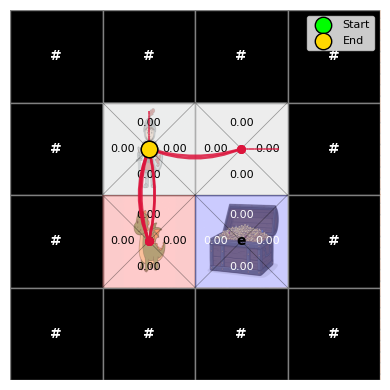

In [4]:
# We create this array for easy access to possible knight actions
knight_actions = np.array([0, 1, 2, 3])

def my_reward_11(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    return 0.0

def my_action_11(state, q_value):
	# <implement your action here>
    return np.random.choice(knight_actions)
	# return ... (int)

def my_Q_update_11(agent, state, action, reward, next_state, dungeon):
    return None # use None for now

treasure_room = make_treasure_room()
vis_11 = DungeonVisualization(treasure_room)

drunken_knight = DungeonAgent(n_states=treasure_room.n_states, 
                             choose_action=my_action_11,
                             reward_func=my_reward_11,
                             update_q_values=my_Q_update_11)

# Run the agent for 1 episode & collect states, actions, rewards
states, actions, rewards = drunken_knight.run_episode(treasure_room, nstep=10, gamma=1.0)

# Show the map, Q-values, and path.
vis_11.show(states, actions, drunken_knight.q_values)

### (b)
> Observe how you move and draw a Markov decision process (MDP) diagram for all four non-wall states.

*(Insert your MDP diagram photo/figure here)*

### (c)
> Compute the theoretical probability distribution over a 2-step horizon analytically (without writing code) when you use the stochastic policy you implemented.


### (d)
> If you implement Q-learning with an episode length of 1 (`nstep = 1`) under current setup, will you manage to perform better? Why or why not? Explain your reasoning.


### (e)
> For a dungeon of width $N$ and height $M$, what is the minimum number of steps required to reach the goal from the starting position? Why? 


---
### 1.2 A tricky knight in an underground maze

### (a)
> (a) Using your stochastic policy $\pi$, implement the Q-learning update with a discount factor ($\gamma = 1$) and a maximum episode length of 30 steps ($n_{\text{step}} = 30$). Run consecutive episodes without resetting the Q-table. Explain your observations on how the Q-values change relative to the goal and starting locations.

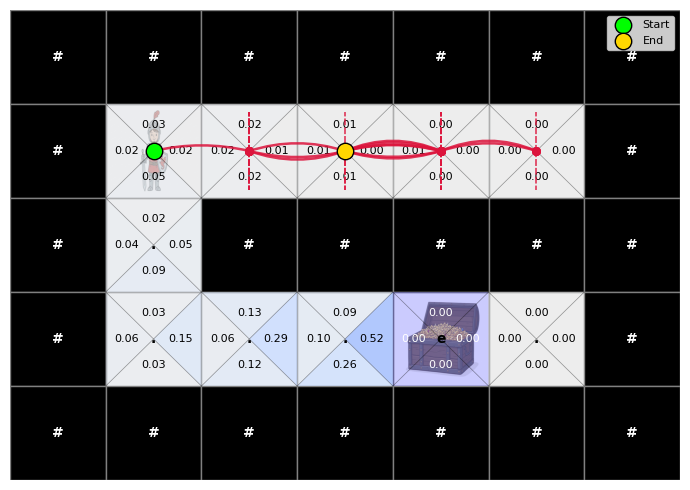

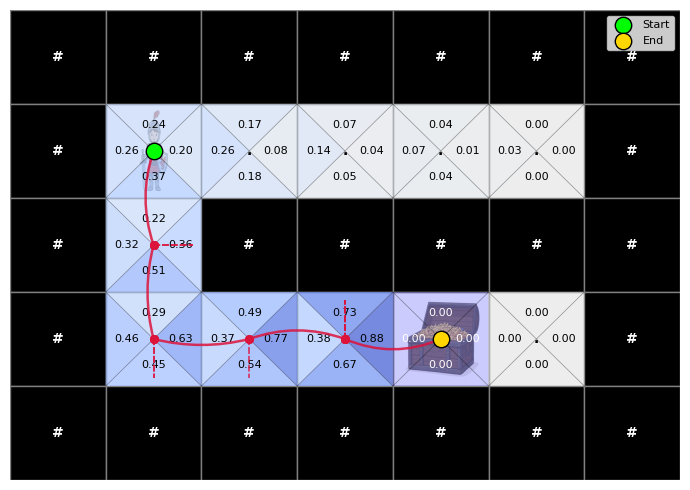

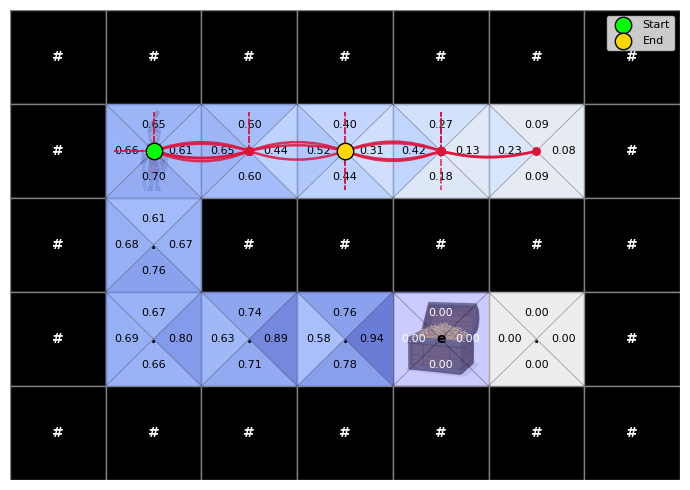

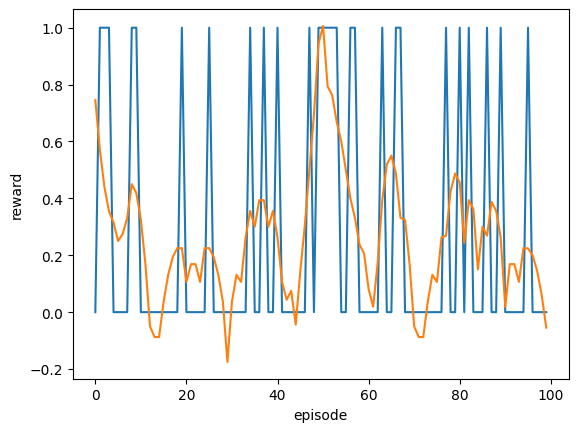

In [5]:
discount_factor = 1 # Gamma
learning_rate = 0.1 # Sweet spot for most tabular Q-learning

def my_reward_12(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    return 0.0

def my_action_12(state, q_values):
    return np.random.choice(4) 

def my_Q_update_12(agent, state, action, reward, next_state, dungeon):
	# <implement your Q update here>
    # Hint: lecture 8, page 18 <20/29>
    current_q = agent.q_values[action, state]

    # We transpose q_values to easily access them via state
    temporal_diff = reward + (discount_factor * np.max(agent.q_values.T[next_state])) - current_q
    new_current_q_value = current_q + learning_rate * temporal_diff
    
    agent.q_values[action, state] = new_current_q_value
    ## TODO: Return really needed???
    return new_current_q_value

underground_maze = make_underground_maze(p_slippery=0.0)
vis_12 = DungeonVisualization(underground_maze)

tricky_knight = DungeonAgent(n_states=underground_maze.n_states, 
                             choose_action=my_action_12,
                             reward_func=my_reward_12,
                             update_q_values=my_Q_update_12)

training_reward = []
# program your knight here
# compute episodic reward
# append "training_reward"


for i in range(100):
    states, actions, rewards = tricky_knight.run_episode(underground_maze, nstep=30, gamma=discount_factor)
    if (i % 33 == 0 and i != 0):
        vis_12.show(states, actions, tricky_knight.q_values)
    training_reward.append(np.sum(rewards))
# plot "training_reward"
vis_12.plot_training_reward(training_reward)

In [6]:
# TODO: Maybe add more stuff to this?

# Observations
---------
As the agent runs episodes, the Q-Values first get bigger towards the treasure.

Then, the Q-Values seem to propagate (as in get bigger) towards the spawn point.

Finally, they seem to propagate towards the rest of the dungeon.

## Important
This propagation occurs, in a more intense way, in the actions that lead to the correct path to the treasure.

### (b)
> By varying the discount factor $\gamma$, do you observe any differences? Summarize how the discount rate affects the results and explain why it is necessary.


We will 3 agents with the discount factors: 0.1, 0.5 and 0.7.



AGENT WITH DISCOUNT FACTOR OF 0.1: 




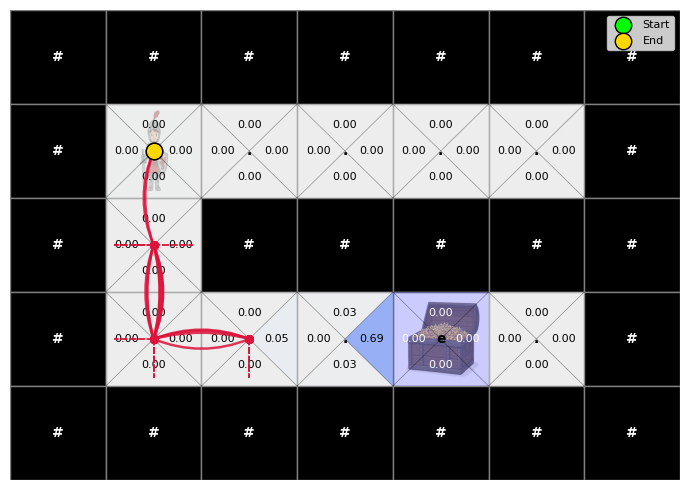

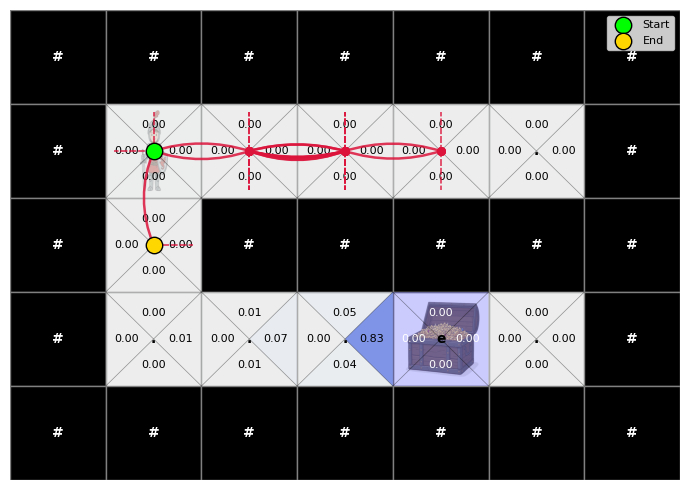

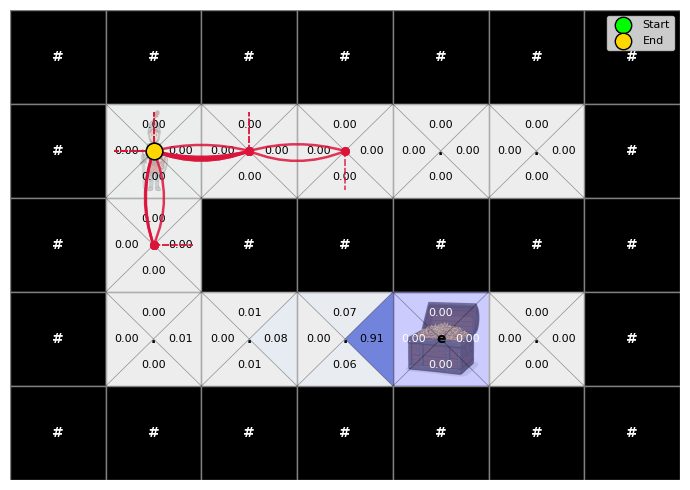

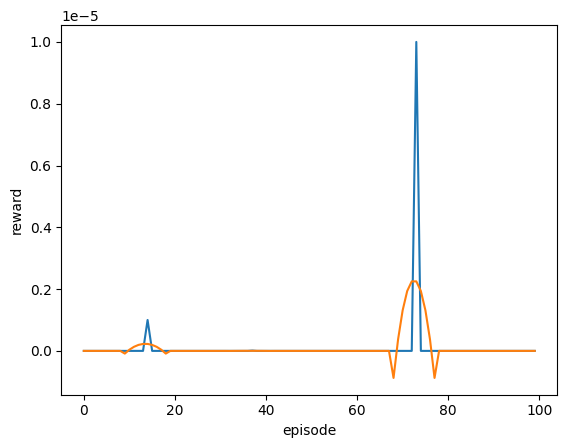



AGENT WITH DISCOUNT FACTOR OF 0.5: 




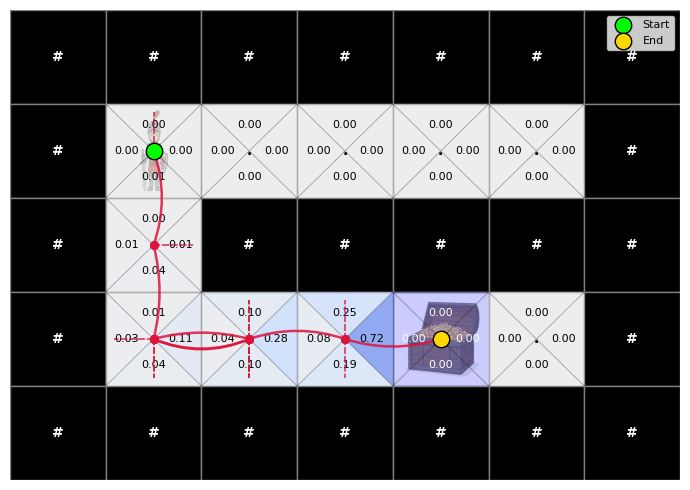

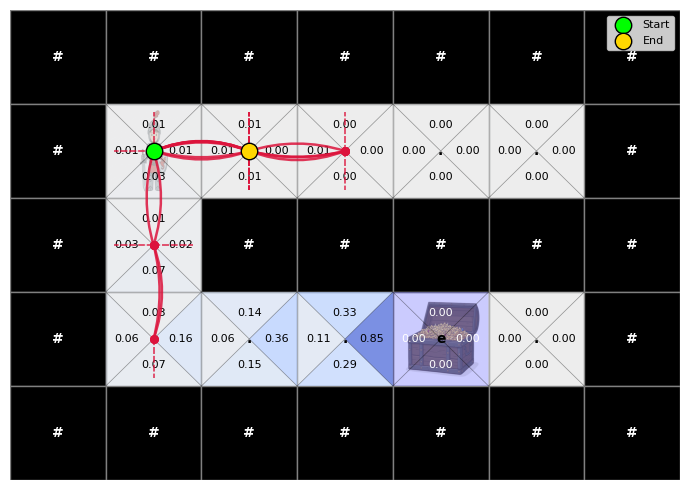

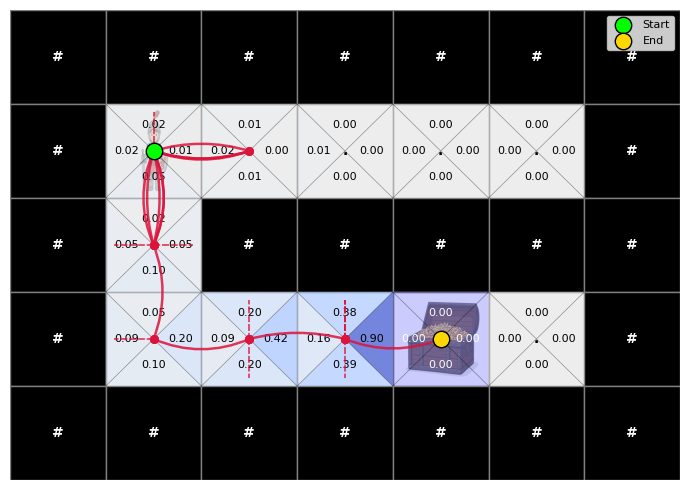

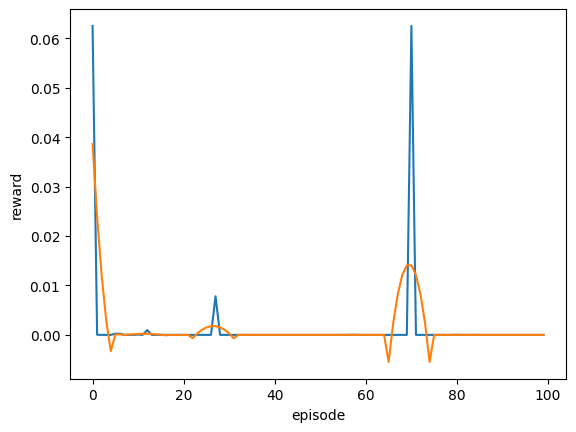



AGENT WITH DISCOUNT FACTOR OF 0.7: 




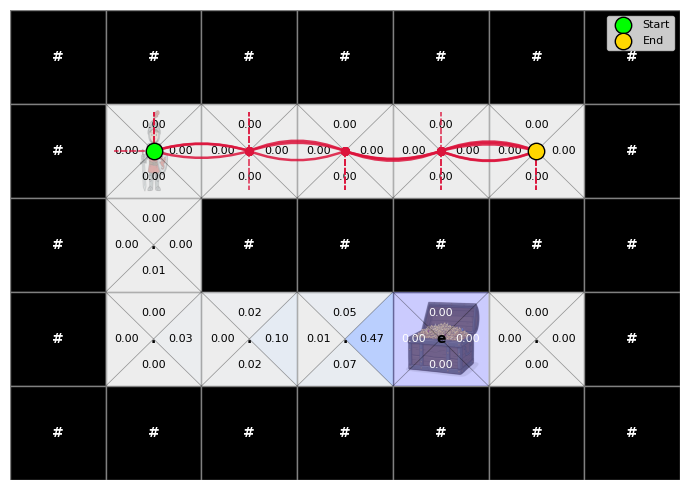

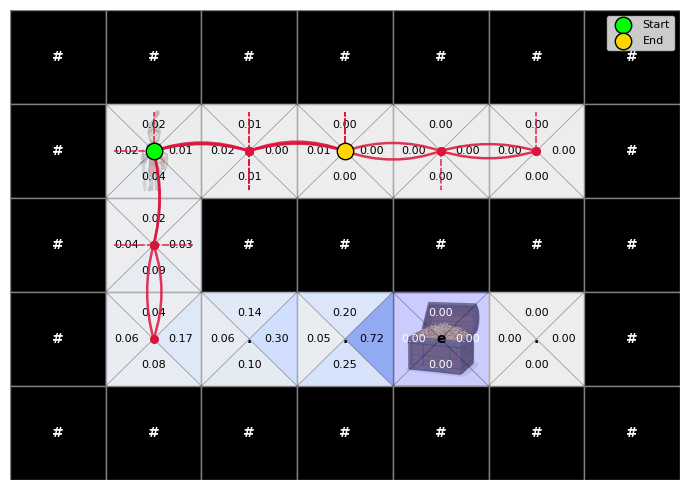

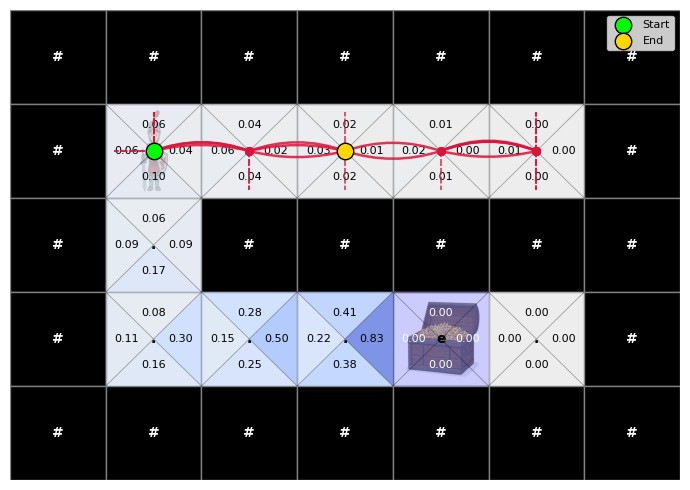

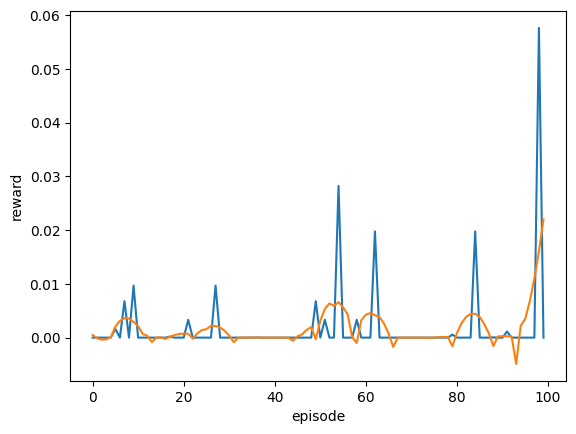

In [7]:
discount_factors_dic = {0: 0.1, 1: 0.5, 2: 0.7}
for i in range(3):
    discount_factor = discount_factors_dic[i]
    print(f"\n\nAGENT WITH DISCOUNT FACTOR OF {discount_factor}: \n\n")
    learning_rate = 0.1

    underground_maze = make_underground_maze(p_slippery=0.0)
    vis_12 = DungeonVisualization(underground_maze)

    tricky_knight = DungeonAgent(n_states=underground_maze.n_states,
                                 choose_action=my_action_12,
                                 reward_func=my_reward_12,
                                 update_q_values=my_Q_update_12)

    training_reward = []
    for i in range(100):
        states, actions, rewards = tricky_knight.run_episode(
            underground_maze, nstep=30, gamma=discount_factor)
        if (i % 33 == 0 and i != 0):
            vis_12.show(states, actions, tricky_knight.q_values)
        training_reward.append(np.sum(rewards))
    # plot "training_reward"
    vis_12.plot_training_reward(training_reward)

# Summary of the observations
---------
We found that the discount factor changes how fast the Q-Values are propagated towards the spawn point:

A low discount factor makes it so that the propagation of the Q-Values is a lot slower. The more we increase the discount factor, the quicker the values propagate.
# Why it is necessary
---------
The discount factor needs to be implemented to limit how fast Q-Values grow.

### (c)
> Implement an $\epsilon$-greedy policy for your agent by varying $\epsilon$. Plot the sum of discounted rewards per episode over 100 training runs and explain your observations.



AGENT WITH EPSILON OF 0.1: 




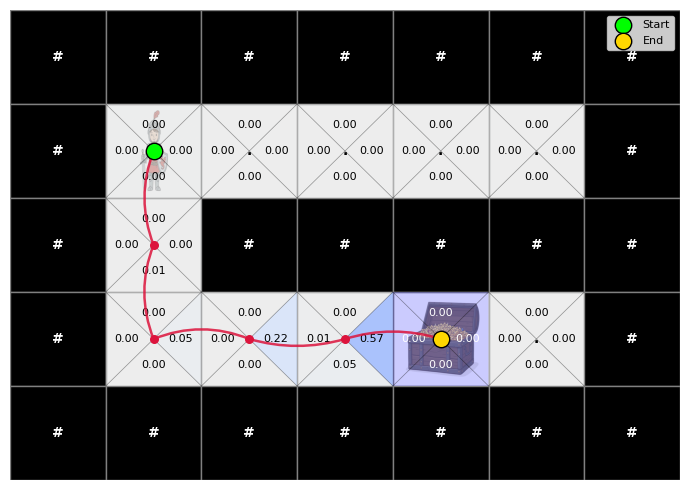

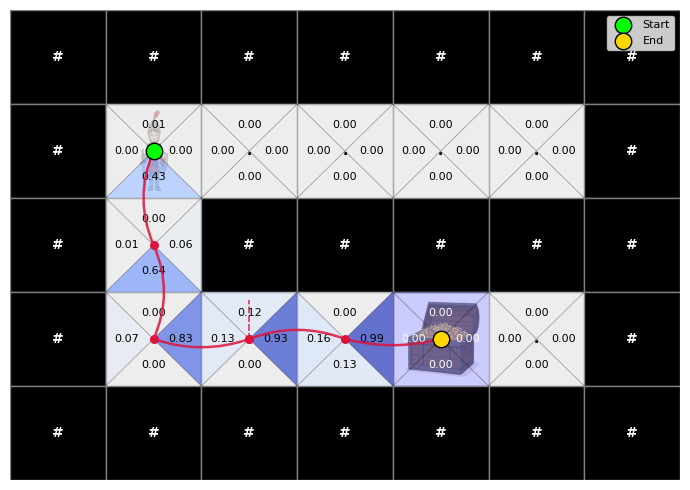

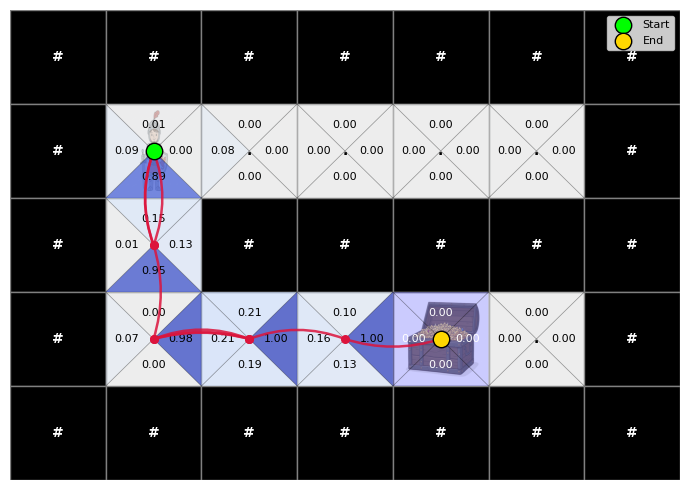

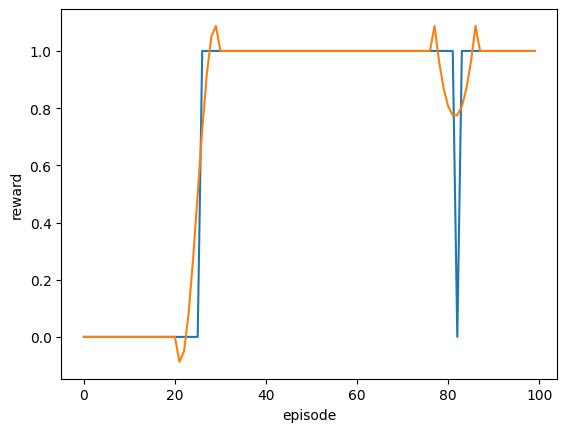



AGENT WITH EPSILON OF 0.3: 




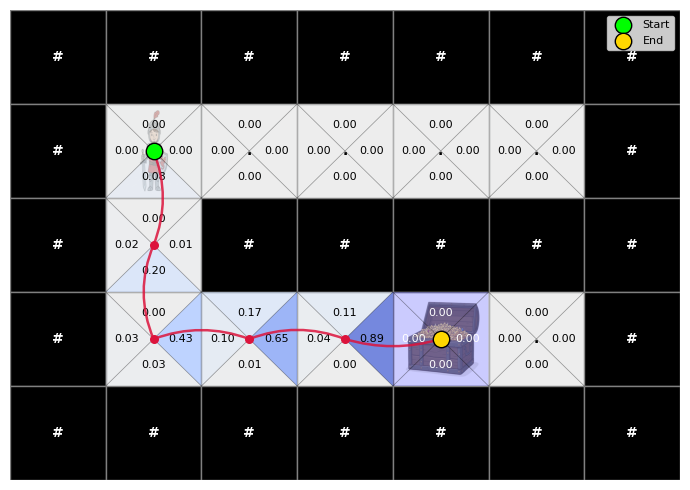

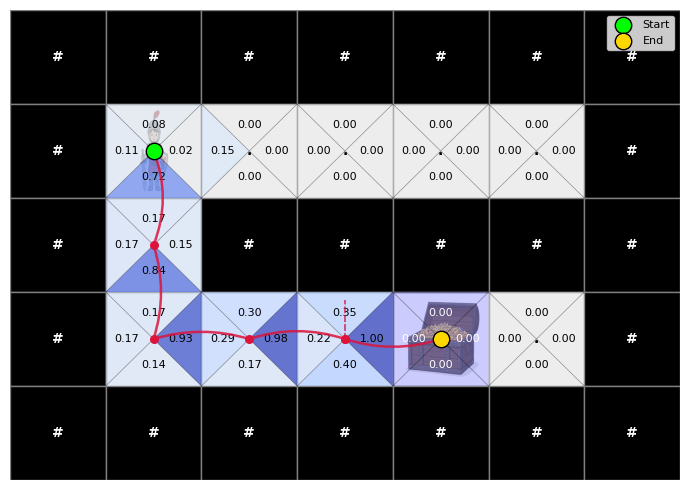

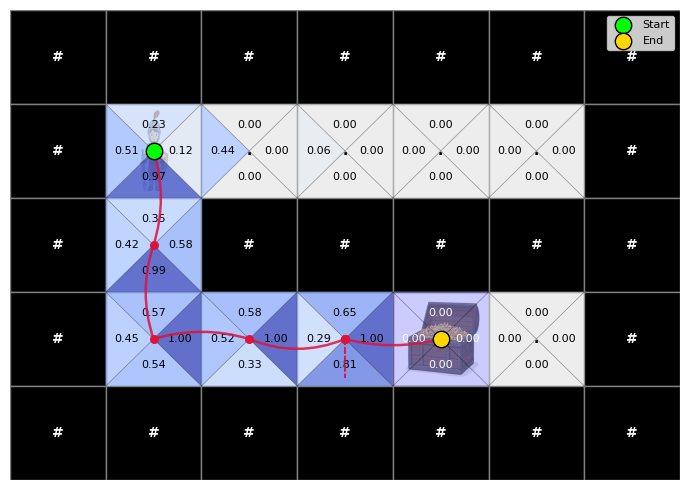

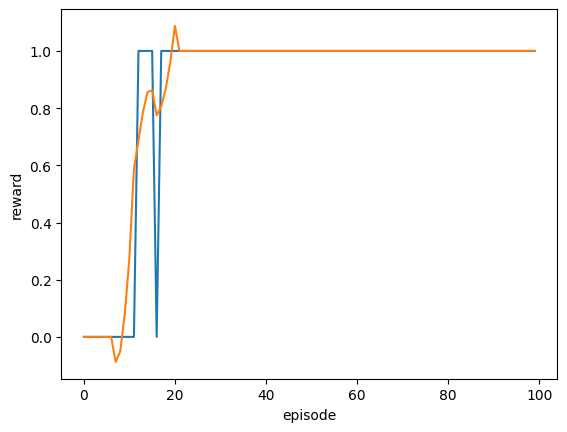



AGENT WITH EPSILON OF 0.7: 




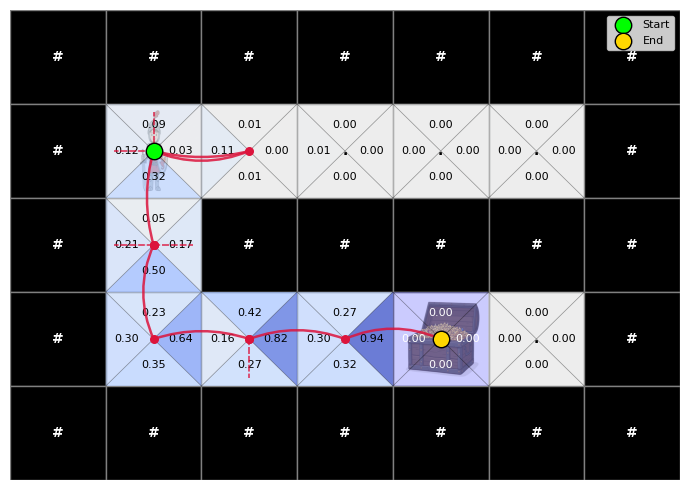

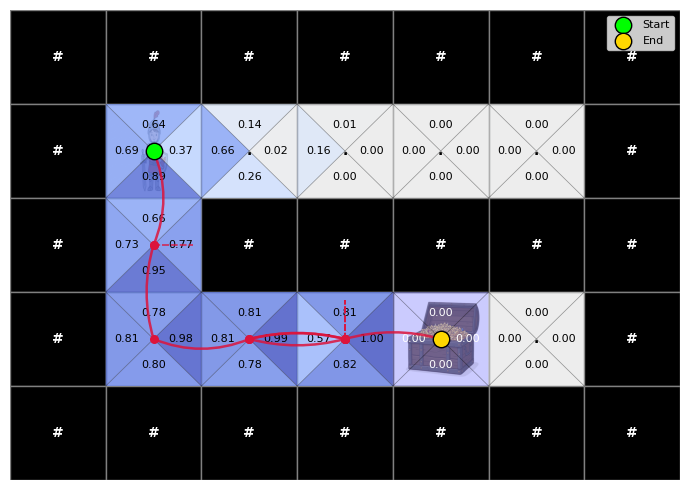

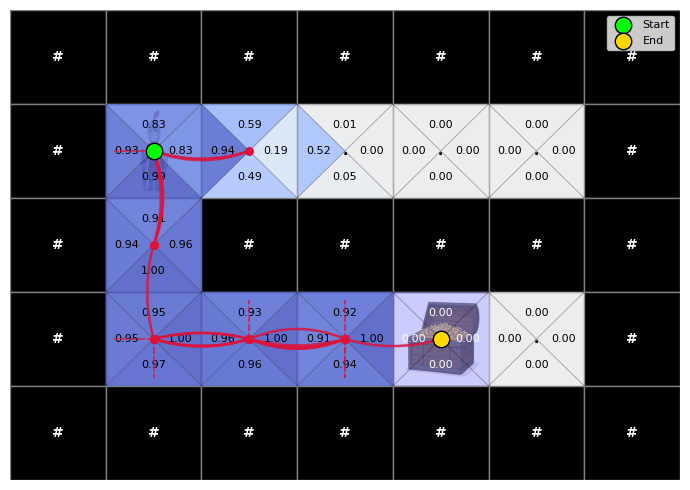

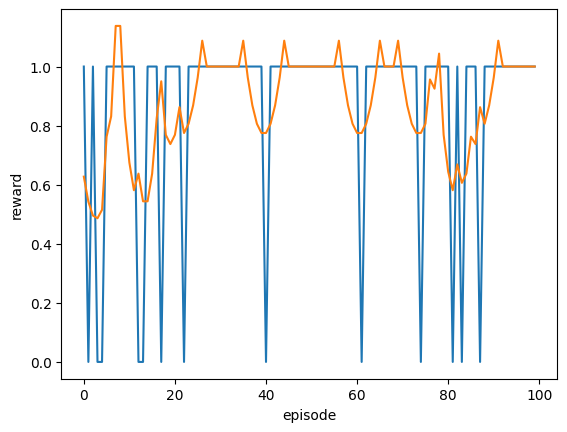

In [11]:
import random

discount_factor = 1 # Gamma
learning_rate = 0.1 # Sweet spot for most tabular Q-learning

def my_greedy_action(state, q_values):
    if random.random() <= epsilon:
        # Case: Not Greedy
           return np.random.choice(4)
    else:
        # Case: Greedy
        return q_values.T[state].argmax()
        
epsilon_dic = {0: 0.1, 1: 0.3, 2: 0.7}
epsilon = 0
for i in range(3):
    epsilon = epsilon_dic[i]
    
    print(f"\n\nAGENT WITH EPSILON OF {epsilon}: \n\n")

        
    underground_maze = make_underground_maze(p_slippery=0.0)
    vis_12 = DungeonVisualization(underground_maze)

    tricky_knight = DungeonAgent(n_states=underground_maze.n_states, 
                                choose_action=my_greedy_action,
                                reward_func=my_reward_12,
                                update_q_values=my_Q_update_12)

    training_reward = []
    # program your knight here
    # compute episodic reward
    # append "training_reward"

    for i in range(100):
        states, actions, rewards = tricky_knight.run_episode(underground_maze, nstep=30, gamma=discount_factor)
        if (i % 33 == 0 and i != 0):
            vis_12.show(states, actions, tricky_knight.q_values)
        training_reward.append(np.sum(rewards))
    # plot "training_reward"
    vis_12.plot_training_reward(training_reward)

# Observations
---------
The closer epsilon gets to 1, the closer the agent's behaviour becomes the same as the prior ones (all random).

The closer epsilon gets to 0, the less random the propagation of the Q-Values from the treasure to the spawn point becomes: The path to the treasure contains the highest Q-Values of the map.

### (d)
> Is a single training run sufficient to evaluate and compare an agent’s performance across different hyperparameter settings? Specifically: (i) Will an agent reach the goal on every evaluation episode? Explain why or why not. (ii) Under what specific conditions would RL training and evaluation results be strictly deterministic and reproducible? And (iii) Given these factors, how should an RL agent's performance be properly evaluated and compared, both when those deterministic conditions are met and when they are not?

# Sub-Points Answer
---------
## i)
Whether or not an Agent reaches the goal on an evaluation episode across different hyperparameter settings is entirely dependant on both the hyperparameters themselves and randomness:

For hyperparameters: Changing a hyperparameter can cause an episode to either reach the goal efficiently, or make it impossible to do so. Example: changing the number of steps to a very low number can make it impossible for an Agent to reach its goal.

For randomness: If randomness is a factor in an episode, then the event where an Agent reaches their goal is entirely dependant on luck. Example: A high epsilon value will make the results of an episode very inconsistent.
## ii)
For random results, we would have to use a seed-based randomness system (such as using a number to influence the outcome of RNG), in order to obtain reproducible results.

If our system is entirely greedy, we would not have to do anything, as it would be reproducible by default.
## iii)
In a deterministic scenario (deterministic conditions are met)
- The performance of an Agent should rely on the quality of their Q-Values.
- Only 1 hyperparemeter should be changed per evaluation in order to ascertain which hyperparemeter changes what and by what amount.
In a non-deterministic scenario (deterministic conditions are not met):
- Evaluation should be done as stated above.
- What should change is the usage of multiple, independant episodes on the same Agent.
- A singular episode will not work, as it is way to unpredictable.
# Answer
---------
So, the answer to "Is a single training run sufficient to evaluate and compare an agent’s performance across different hyperparameter settings?" is:

It depends. If we are in a deterministic scenario, it COULD be possible to compare the Agent's performance across multiple hyperparameter settings. However, if we are in a non-deterministic scenario, comparing hyperparameter changes is not feasible due to the unpredictability of the outcomes.

### (e)
> Recreate the maze using `make_underground_maze_with_meat()`, update the reward function, set $\epsilon = 0.9$, $n_{\text{step}} = 50$, and $\gamma = 0.95$, and run the agent for 100 to 200 training runs. Explain your observations regarding your strategy (Q-values) and behavior.

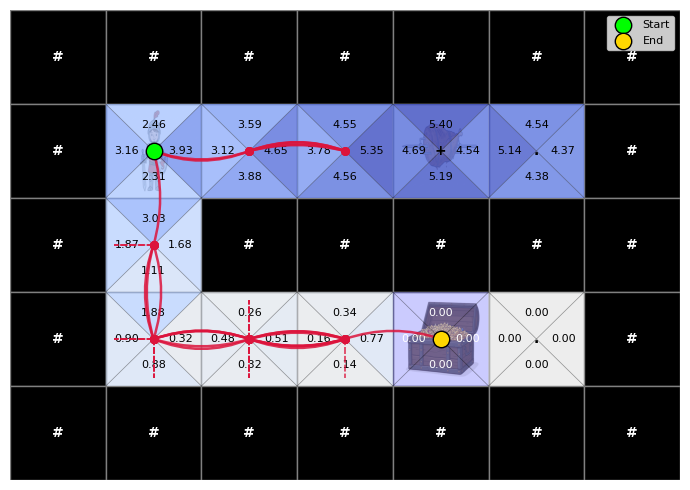

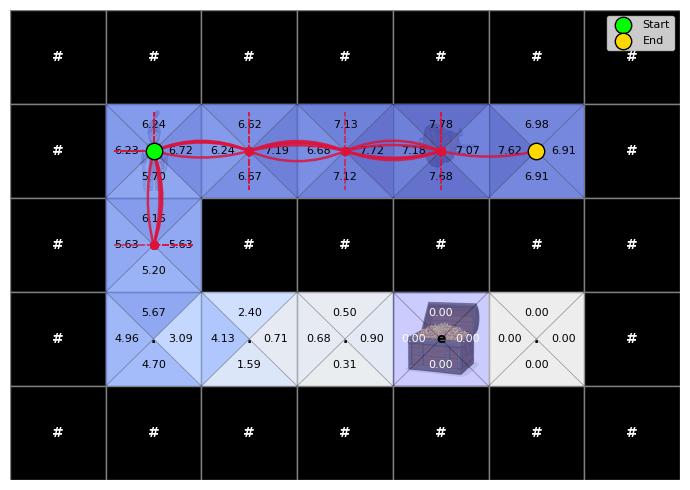

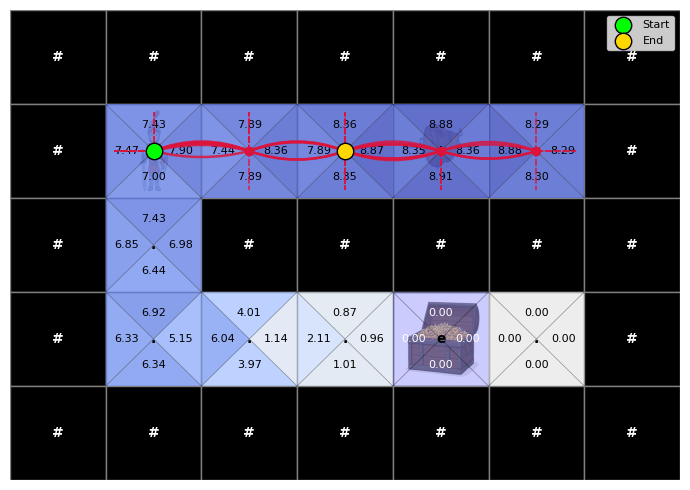

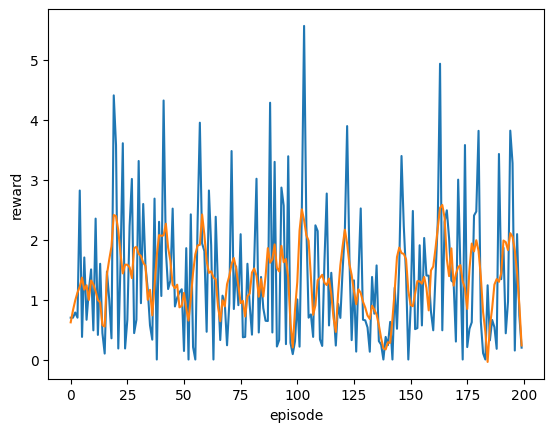

In [24]:
discount_factor = 0.95 # Gamma
learning_rate = 0.1 # Sweet spot for most tabular Q-learning
epsilon = 0.9

def my_reward_12(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    if dungeon.tiles[next_state] == "+":
        return 0.5
    return 0.0
        
underground_maze = make_underground_maze_with_meat(p_slippery=0.0)
vis_12 = DungeonVisualization(underground_maze)

tricky_knight = DungeonAgent(n_states=underground_maze.n_states, 
                                choose_action=my_greedy_action,
                                reward_func=my_reward_12,
                                update_q_values=my_Q_update_12)

training_reward = []
# program your knight here
# compute episodic reward
# append "training_reward"

for i in range(200):
    states, actions, rewards = tricky_knight.run_episode(underground_maze, nstep=50, gamma=discount_factor)
    if (i % 50 == 0 and i != 0):
        vis_12.show(states, actions, tricky_knight.q_values)
    training_reward.append(np.sum(rewards))
# plot "training_reward"
vis_12.plot_training_reward(training_reward)

# Observations
---------
Upon adding the meat to the dungeon, the Agent seems to favor it over the treasure. This is reflected on the Q-Values: they are a lot stronger in the path towards the meat than the path towards the treasure.

> (f) Compare the state values $V(s)$ when you go directly to the treasure (e), collects free meat as you observed (+), or do both. Explain your results mathematically.


> (g) How might you modify the reward function or environment design to prevent this *reward hacking*? Propose and explain a solution. (Bonus)

# Proposal
---------
If we could modify the environment design, we would make it so that the Agent can only collect the meat once, which is currently not the case. We believe that right now, the Agent is constantly getting in and out of the meat cell in order to "farm reward points". Removing the meat once reaching it the first time would help agains't the reward hacking.

## Part 2: Bayesian Decision-Making in Multi-Armed Bandits

### 2.1 Bayesian Estimation of Arm Rewards

### (a)
> Starting from Bayes' theorem and the Bernoulli likelihood, derive the posterior distribution $p(\theta \mid D)$ and identify its updated parameters. Hence, show that the Beta distribution is a conjugate prior to the Bernoulli likelihood. 

### (b)
> Suppose the prior is $(\beta(2,2))$. After ten pulls, the arm produces seven successes and three failures. Compute the posterior distribution and posterior mean. Show that, in general, the posterior mean can be expressed as a weighted average of the prior mean and the empirical success rate. Interpret the weights and explain how they change as the number of observations increases

### 2.2 Learning with Thompson Samplin

### (a)
> Implement a five-armed Bernoulli bandit environment that generates binary rewards using the given success probabilities. Then implement a Thompson sampling agent that maintains the posterior parameters for each arm, selects actions using posterior sampling, and updates the corresponding posterior after receiving each reward. 

### (b)
> Using the results from part (a), plot the evolution of the posterior mean estimates for all five arms as a function of time; visualize the posterior distributions; discuss how the posterior means and distributions evolve; and explain why some arms become more certain about their estimated success probabilities than others.

### 2.3 Experimental Evaluation and Exploration

### (a)
> Perform 100 independent trials of Thompson sampling, each consisting of 2,000 decisions. Initialize a new agent with the same priors at the beginning of every trial.

### (b)
> Derive the agent's expected reward per decision and its expected instantaneous pseudo-regret. Hence, derive the expected cumulative pseudo-regret $\mathbb{E}[\mathcal{R}_T]$. How does it grow with $T$, assuming $\epsilon$ remains fixed and the greedy choice remains optimal? (Bonus)

### (c)
> Compare $\epsilon$-greedy exploration with Thompson sampling. Explain why Thompson sampling may select an arm with a lower posterior mean and how its exploration behavior changes as more observations accumulate.